# Extended Figure 2 — per-region SNV & indel spectra + VAF

For the seven cross-platform concordance regions, in three groups (the all-three core, the
three pairwise overlaps and the three platform-private sets), per region: the absolute number of
variants, the mutational profile (SNV 96-context / indel COSMIC ID-83) and the tumour VAF
distribution per member platform. Restricted to the
VAF >= 10% inclusion gate.

The published figure uses the five cell lines sequenced on Illumina, Roche and Ultima,
tumour/normal. Point the Configuration cell at other runs — or your own oncoanalyser output —
and run all cells; see **Data access** below.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

### What this notebook reads (~150 MB)

Fifteen run folders — 5 cell lines x 3 platforms, WGS, tumour/normal — and one file from each:

```text
gs://hartwig-oapaper-celllines/<cell line>/wgs/<platform>/bwa/tn/oa3/
  purple/<tumour>.purple.somatic.vcf.gz     every panel
```

`<cell line>` is COLO829, HCC1187, HCC1395, HCC1954 or HG008; `<platform>` is
`illumina_novaseq6000`, `roche_sbx` or `ultima_ug100`. Everything the figure shows — the
96-context SNV channel, the COSMIC ID-83 indel channel and the VAF — is read from the
`TNC`, `REP_C`/`REP_S`, `RC_MH` and `AF` fields of those VCFs, so no reference genome is
needed.

Figure 2 reads the same VCFs into `data/purple/`; this notebook caches its own copy under
`data/extended_figure_2/`.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs (sizes above), then repoint the
Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for CL in COLO829 HCC1187 HCC1395 HCC1954 HG008; do
  for P in illumina_novaseq6000 roche_sbx ultima_ug100; do
    gcloud storage rsync -r \
      gs://hartwig-oapaper-celllines/$CL/wgs/$P/bwa/tn/oa3/purple \
      $DEST/$CL/wgs/$P/bwa/tn/oa3/purple
  done
done          # ~2 GB: the purple/ folders, plots and all
```

Then, in the Configuration cell:

```python
CELLLINES_ROOT = "/absolute/path/to/oapaper-data"   # the $DEST above
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The
only requirement is that the directory contains the tool sub-folders listed above; the
sample names are read from the files themselves, so they do not have to match ours.


## 1 · Configuration

In [1]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# A run folder is addressed by its fields rather than hard-coded, using the
# scheme described in Data access above:
#
#   <CELLLINES_ROOT>/<cell line>/<MODALITY>/<platform>/<ALIGNER>/<RUN_TYPE>/<PIPELINE>
#
# run_dir() assembles that path and every loader goes through it, so switching
# to a local copy is a one-line change to CELLLINES_ROOT.
# ============================================================================
CELLLINES_ROOT = "gs://hartwig-oapaper-celllines"   # or an absolute path to a local copy

PLATFORMS = OrderedDict([                      # label -> bucket folder + plot colour
    ("Illumina", {"dir": "illumina_novaseq6000", "color": "#E08214"}),
    ("Roche",    {"dir": "roche_sbx",            "color": "#2C6FBB"}),
    ("Ultima",   {"dir": "ultima_ug100",         "color": "#3A3A3A"}),
])
CELL_LINES = ["COLO829", "HCC1187", "HCC1395", "HCC1954", "HG008"]
MODALITY   = "wgs"       # wgs | panel
ALIGNER    = "bwa"
RUN_TYPE   = "tn"        # tn = tumour/normal | to = tumour-only
PIPELINE   = "oa3"       # oncoanalyser 3.x
# ============================================================================

VAF_MIN   = 0.10     # inclusion gate: keep a variant if tumour FORMAT AF >= this on >=1 platform
CACHE_DIR = Path("data") / "extended_figure_2"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def run_dir(cell_line, platform):
    """The oncoanalyser run folder for one cell line on one platform."""
    return (f"{str(CELLLINES_ROOT).rstrip('/')}/{cell_line}/{MODALITY}"
            f"/{PLATFORMS[platform]['dir']}/{ALIGNER}/{RUN_TYPE}/{PIPELINE}")

print("Cell lines:", CELL_LINES)
for _p in PLATFORMS:
    print(f"  {_p:9s} {run_dir(CELL_LINES[0], _p)}")

Cell lines: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954', 'HG008']
  Illumina  gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3
  Roche     gs://hartwig-oapaper-celllines/COLO829/wgs/roche_sbx/bwa/tn/oa3
  Ultima    gs://hartwig-oapaper-celllines/COLO829/wgs/ultima_ug100/bwa/tn/oa3


## 2 · Plotting style

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11, "axes.titleweight": "bold",
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette (matches Figure 2 panel B)
SBS_CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}

def fmt(n):
    n = float(n)
    return f"{n/1000:.1f}k" if n >= 1000 else f"{n:.0f}"

## 3 · Load per-variant data (SNV 96-context + indel ID-83)

In [3]:
import subprocess, re, gzip
import numpy as np
import pandas as pd

def _ls(path):
    if str(path).startswith("gs://"):
        r = subprocess.run(["gsutil", "ls", str(path)], capture_output=True, text=True)
        return [l for l in r.stdout.splitlines() if l.strip()]
    p = Path(path)
    return [str(c) + ("/" if c.is_dir() else "") for c in p.iterdir()] if p.exists() else []

def _fetch(src, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        return dest
    if str(src).startswith("gs://"):
        subprocess.run(["gsutil", "cp", str(src), str(dest)], check=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    else:
        import shutil; shutil.copy(Path(src), dest)
    return dest

_PURITY_SUFFIX = ".purple.purity.tsv"

def discover_cell_lines(platform):
    # Return [(cell_line, tumour_sample, base), ...] for one platform. The tumour sample name
    # comes from <run>/purple/<tumour>.purple.purity.tsv rather than from our naming convention.
    found = []
    for cl in CELL_LINES:
        base = run_dir(cl, platform)
        hits = [e for e in _ls(base + "/purple/") if e.endswith(_PURITY_SUFFIX)]
        if not hits:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {cl}/{platform}")
            continue
        found.append((cl, hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)], base))
    return found

def _tumor_vaf(fmt, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt.split(":")
    if "AF" not in keys:
        return np.nan
    v = sample.split(":")[keys.index("AF")]
    try:
        return float(v)
    except ValueError:
        return np.nan

print("io helpers ready")

io helpers ready


In [4]:
# ---- Per-variant data for the seven Venn-region profiles (VAF + mutation channel) --------------
# Re-read the cached PURPLE somatic VCFs to retain, per PASS SNV and per PASS indel:
#   key -> (tumour VAF, mutation channel)
# SNV channel = 96-context (INFO 'TNC', pyrimidine-normalised, matches panel B).
# Indel channel = COSMIC ID-83, derived from REF/ALT + SAGE repeat (REP_C/REP_S) and microhomology
# (RC_MH) annotations (no reference genome needed). Additive: DATA and panels A-D are untouched.
from scipy.stats import gaussian_kde

_COMP = {"A": "T", "T": "A", "C": "G", "G": "C", "N": "N"}
def _rc(s):
    return "".join(_COMP[b] for b in reversed(s))

# ---- SNV: 96 trinucleotide contexts ----
def sbs96_bucket(ref, alt, tnc):
    # 'CLASS_TRI' e.g. 'C>T_ACG'; pyrimidine-normalised so ref is C or T (tnc has the ref in the middle).
    if ref in "CT":
        return f"{ref}>{alt}_{tnc}"
    return f"{_COMP[ref]}>{_COMP[alt]}_{_rc(tnc)}"

BASES = "ACGT"
BUCKETS96 = [f"{cls}_{f5}{cls[0]}{f3}" for cls in SBS_CLASSES for f5 in BASES for f3 in BASES]

# ---- Indel: COSMIC ID-83 channels (canonical order) + SigProfiler colour blocks ----
ID83_CHANNELS = (
    [f"1:Del:{b}:{i}" for b in "CT" for i in range(6)]           # 1bp deletion  (homopolymer len 1..6+)
    + [f"1:Ins:{b}:{i}" for b in "CT" for i in range(6)]         # 1bp insertion (0..5+ copies)
    + [f"{s}:Del:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]   # >1bp del at repeats
    + [f"{s}:Ins:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]   # >1bp ins at repeats
    + [f"{s}:Del:M:{j}" for s, n in ((2, 1), (3, 2), (4, 3), (5, 5)) for j in range(1, n + 1)]  # microhomology del
)
assert len(ID83_CHANNELS) == 83, len(ID83_CHANNELS)

ID83_BLOCK_COLORS = {
    "1:Del:C": "#FDBE6F", "1:Del:T": "#FF8001", "1:Ins:C": "#B0DD8B", "1:Ins:T": "#36A02E",
    "2:Del:R": "#FCC9B4", "3:Del:R": "#FC896B", "4:Del:R": "#F04432", "5:Del:R": "#BC141A",
    "2:Ins:R": "#CFE0F1", "3:Ins:R": "#93C4DE", "4:Ins:R": "#4A97C7", "5:Ins:R": "#1863AA",
    "2:Del:M": "#E1E1EE", "3:Del:M": "#B5B5D8", "4:Del:M": "#8683BD", "5:Del:M": "#61409B",
}
def id83_color(ch):
    return ID83_BLOCK_COLORS[":".join(ch.split(":")[:3])]

def _info_get(info, key, cast=str):
    m = re.search(rf"(?:^|;){key}=([^;]+)", info)
    return cast(m.group(1)) if m else None

def classify_id83(ref, alt, info):
    # Map an anchored indel (ref[0] == alt[0]) to a COSMIC ID-83 channel using SAGE annotations.
    is_del = len(ref) > len(alt)
    seq = ref[1:] if is_del else alt[1:]           # deleted / inserted bases (after the anchor base)
    size = len(seq)
    if size == 0:
        return None
    rep_c = _info_get(info, "REP_C", int) or 0
    rep_s = _info_get(info, "REP_S")
    mh = _info_get(info, "RC_MH") or ""
    if size == 1:
        base = seq if seq in "CT" else _COMP[seq]  # pyrimidine-normalise the indel base
        unit_is_base = (rep_s == seq)
        if is_del:
            hp = rep_c if (unit_is_base and rep_c >= 1) else 1     # homopolymer length in reference
            return f"1:Del:{base}:{min(hp - 1, 5)}"
        copies = rep_c if unit_is_base else 0                      # existing copies before insertion
        return f"1:Ins:{base}:{min(copies, 5)}"
    scat = min(size, 5)                                            # size class 2,3,4,5(=5+)
    is_repeat = rep_s is not None and rep_c >= 1 and size % len(rep_s) == 0
    if is_del and not is_repeat and len(mh) >= 1:                 # microhomology-mediated deletion
        cap = {2: 1, 3: 2, 4: 3, 5: 5}[scat]
        return f"{scat}:Del:M:{min(len(mh), cap)}"
    typ = "Del" if is_del else "Ins"
    return f"{scat}:{typ}:R:{min(rep_c, 5) if is_repeat else 0}"

# The seven Venn regions (A = Illumina, B = Roche, C = Ultima), matching panel D, ordered
# shared by all three -> shared by two -> platform-private.
BIN_ORDER = [
    ("All three",       ("Illumina", "Roche", "Ultima")),
    ("Illumina–Roche",  ("Illumina", "Roche")),
    ("Illumina–Ultima", ("Illumina", "Ultima")),
    ("Roche–Ultima",    ("Roche", "Ultima")),
    ("Illumina only",   ("Illumina",)),
    ("Roche only",      ("Roche",)),
    ("Ultima only",     ("Ultima",)),
]
# The three groups the regions fall into: (group name, colour, regions in BIN_ORDER order).
REGION_GROUPS = [
    ("Shared by all three", "#2E7D32", [l for l, m in BIN_ORDER if len(m) == 3]),
    ("Shared by two",       "#6A3D9A", [l for l, m in BIN_ORDER if len(m) == 2]),
    ("Platform-private",    "#8C6D31", [l for l, m in BIN_ORDER if len(m) == 1]),
]
CHANNELS = {"snv": BUCKETS96, "indel": ID83_CHANNELS}
CH_IDX = {k: {ch: i for i, ch in enumerate(v)} for k, v in CHANNELS.items()}

def parse_variants_pervariant(path):
    # {'snv'|'indel': {(chrom,pos,ref,alt): (vaf, channel)}} for PASS variants.
    snv, indel = {}, {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            key = (c[0], c[1], ref, alt)
            vaf = _tumor_vaf(c[8], c[-1])
            if len(ref) == 1 and len(alt) == 1 and ref != alt:
                m = re.search(r"(?:^|;)TNC=([ACGTN]{3})(?:;|$)", c[7])
                if m:
                    snv[key] = (vaf, sbs96_bucket(ref, alt, m.group(1)))
            elif len(ref) != len(alt):
                ch = classify_id83(ref, alt, c[7])
                if ch:
                    indel[key] = (vaf, ch)
    return {"snv": snv, "indel": indel}

PERVAR = {}
for name in PLATFORMS:
    PERVAR[name] = {}
    for cl, tumor, base in discover_cell_lines(name):
        som = _fetch(f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
                     CACHE_DIR / name / cl / f"{tumor}.somatic.vcf.gz")
        PERVAR[name][cl] = parse_variants_pervariant(som)
    print(f"{name}: (SNV, indel) per cell line = " +
          str({cl: (len(PERVAR[name][cl]['snv']), len(PERVAR[name][cl]['indel'])) for cl in PERVAR[name]}))

def region_bins(kind, vaf_gate=False):
    # Sum the seven Venn regions over the cell lines sequenced on all three platforms.
    # Returns (shared_cell_lines, {region: channel count vector}, {region: {platform: [VAFs]}}).
    # vaf_gate=True applies the same inclusion gate as panel D's VAF10 view: keep a variant only if
    # it reaches VAF >= VAF_MIN on at least one platform (membership stays PASS presence).
    plats = list(PLATFORMS)
    shared = sorted(set.intersection(*[set(PERVAR[p]) for p in plats]))
    idx = CH_IDX[kind]; nch = len(CHANNELS[kind])
    to_bin = {frozenset(members): label for label, members in BIN_ORDER}
    prof = {label: np.zeros(nch) for label, _ in BIN_ORDER}
    vafs = {label: {p: [] for p in plats} for label, _ in BIN_ORDER}
    for cl in shared:
        kv = {p: PERVAR[p][cl][kind] for p in plats}
        keys = {p: set(kv[p]) for p in plats}
        universe = set().union(*keys.values())
        if vaf_gate:
            universe = {k for k in universe
                        if any(k in kv[p] and not np.isnan(kv[p][k][0]) and kv[p][k][0] >= VAF_MIN
                               for p in plats)}
        for k in universe:
            members = frozenset(p for p in plats if k in keys[p])
            label = to_bin.get(members)
            if label is None:
                continue
            mp = next(p for p in plats if k in keys[p])          # channel is platform-independent
            bi = idx.get(kv[mp][k][1])
            if bi is not None:
                prof[label][bi] += 1
            for p in members:
                vafs[label][p].append(kv[p][k][0])
    return shared, prof, vafs

print("per-variant data (SNV 96-context + indel ID-83) + region_bins ready")

Illumina: (SNV, indel) per cell line = {'COLO829': (39476, 712), 'HCC1187': (12358, 1206), 'HCC1395': (43495, 2799), 'HCC1954': (22704, 2907), 'HG008': (9549, 1472)}
Roche: (SNV, indel) per cell line = {'COLO829': (39710, 642), 'HCC1187': (12719, 1426), 'HCC1395': (45333, 2751), 'HCC1954': (23014, 3274), 'HG008': (9865, 1591)}
Ultima: (SNV, indel) per cell line = {'COLO829': (40045, 586), 'HCC1187': (12336, 988), 'HCC1395': (44399, 2470), 'HCC1954': (21916, 1847), 'HG008': (9254, 1158)}
per-variant data (SNV 96-context + indel ID-83) + region_bins ready


## 4 · Per-region SNV profiles — spectrum + VAF

Wrote: figures/molecular_venn_region_profiles.pdf figures/molecular_venn_region_profiles.svg figures/molecular_venn_region_profiles.png


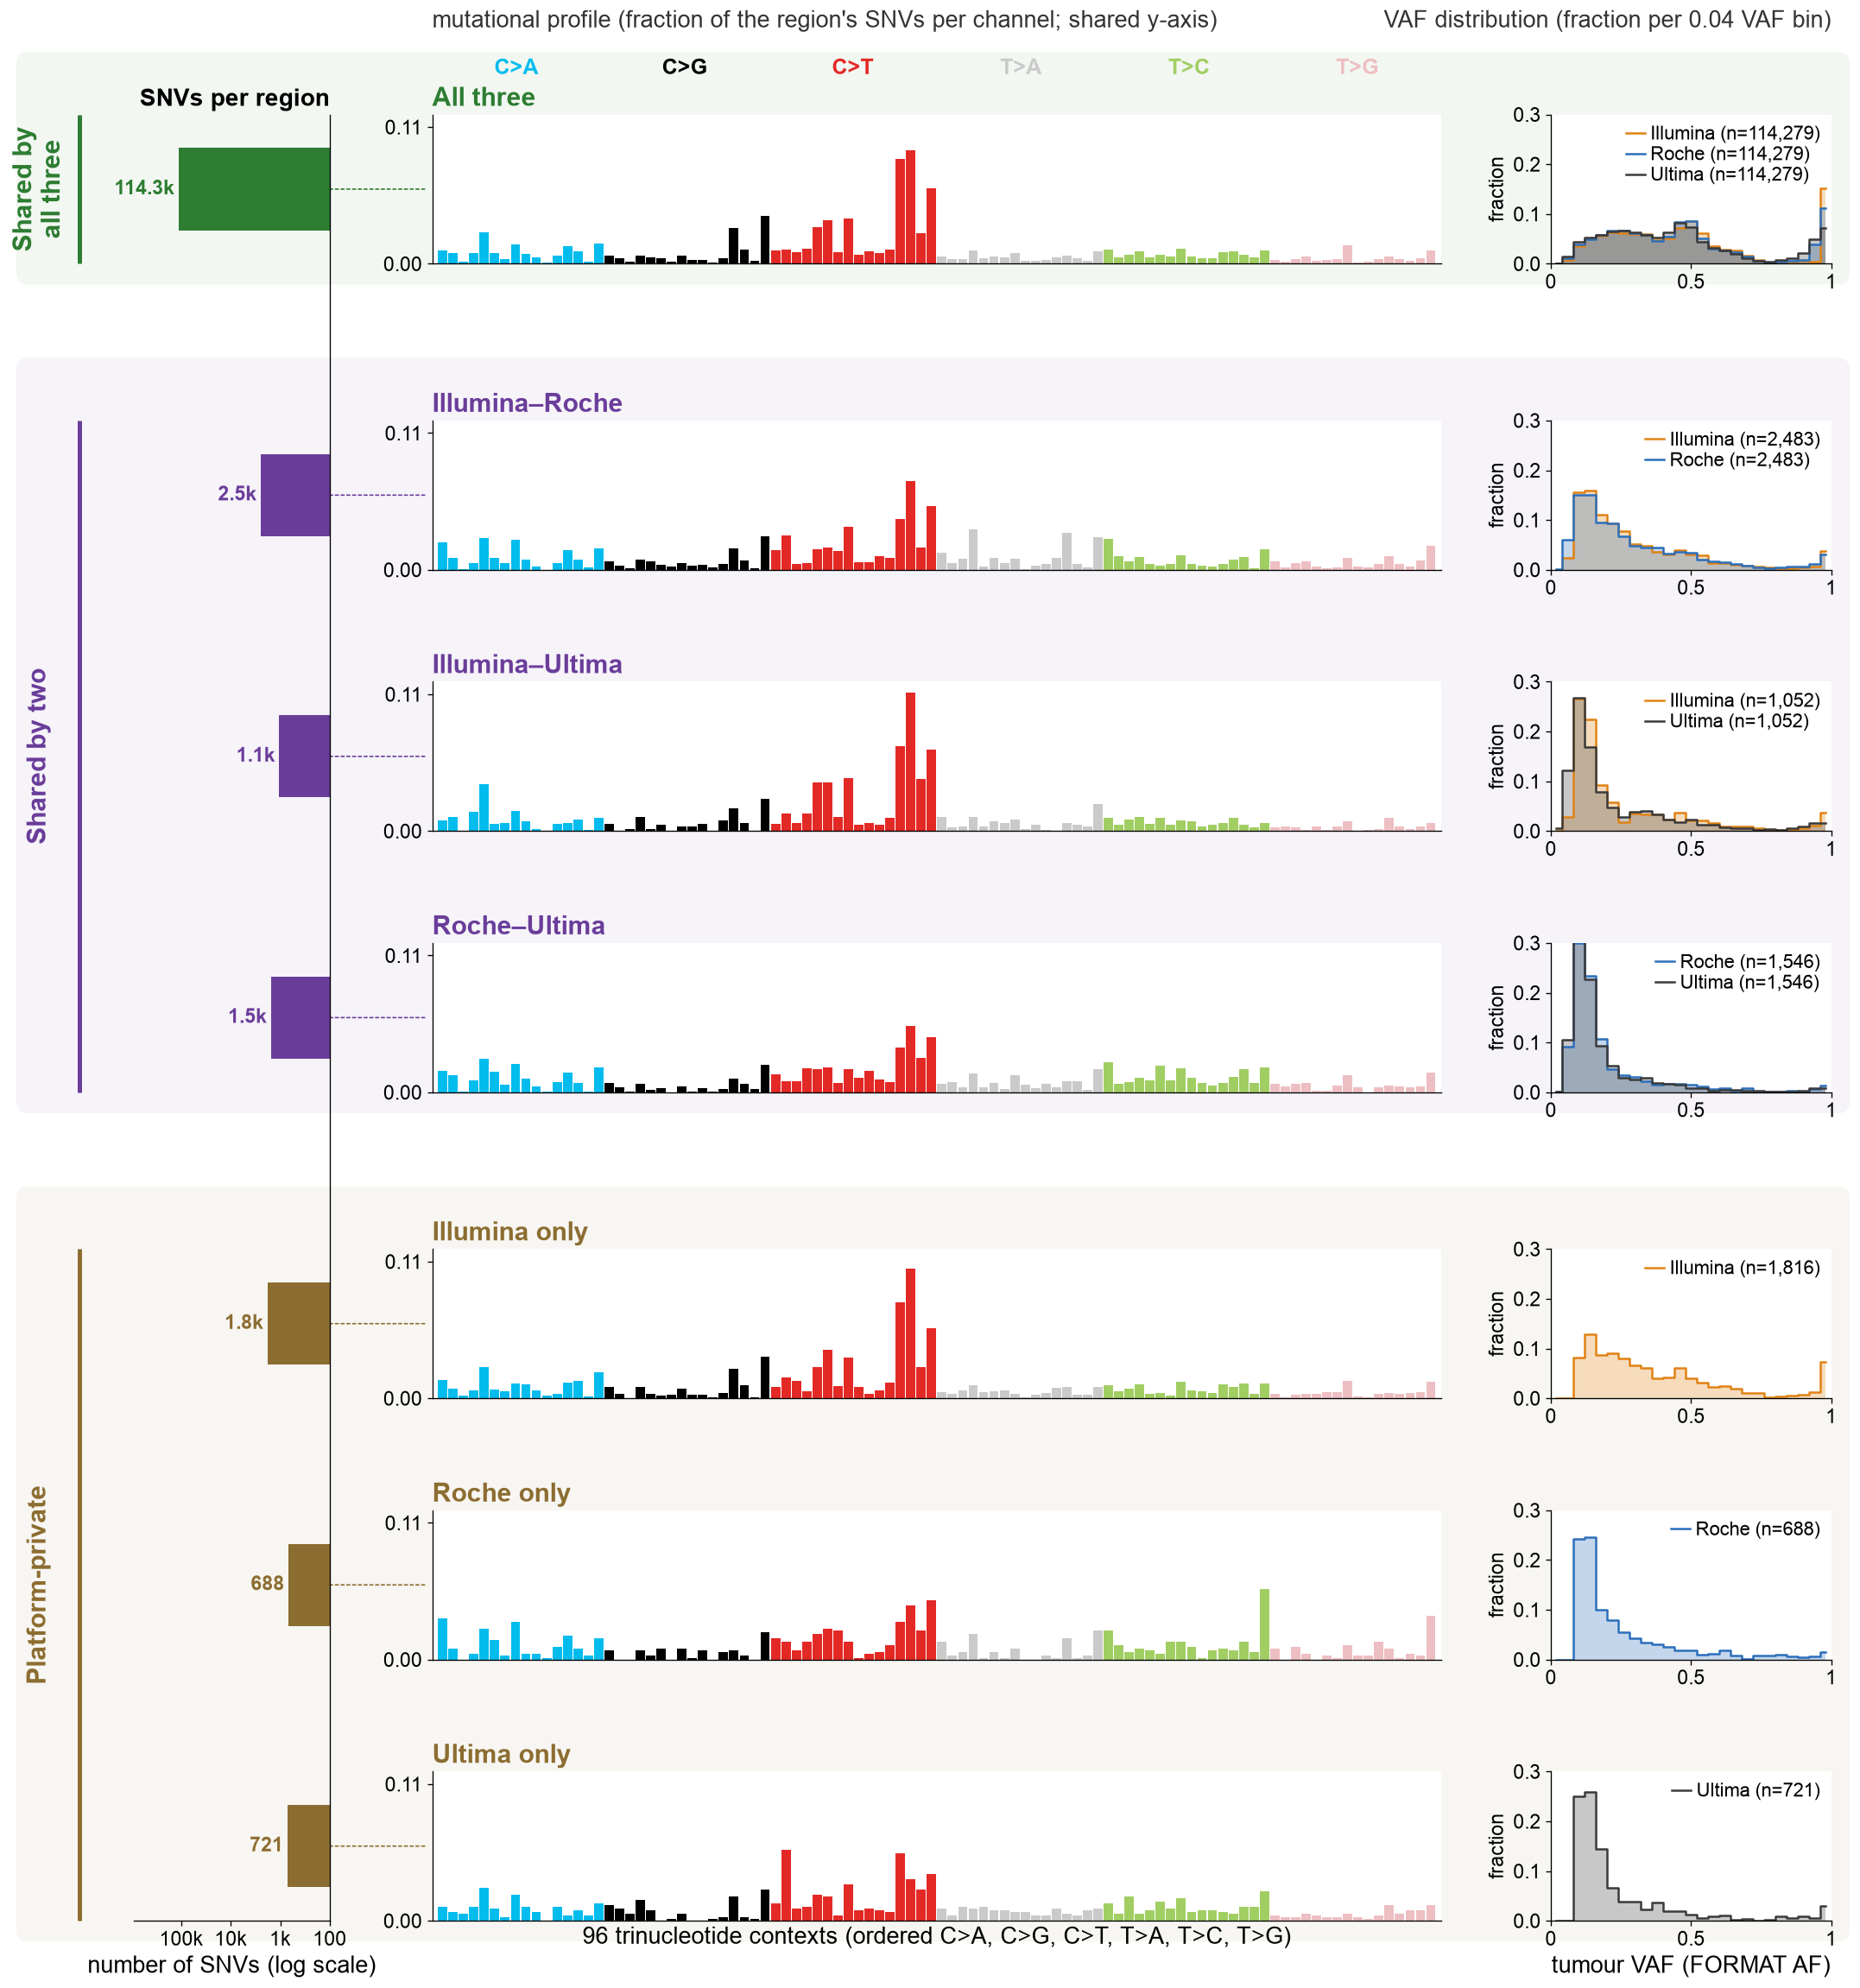

In [12]:
import matplotlib.transforms as mtransforms

VAF_BINS = np.linspace(0, 1, 26)                 # 25 bins, width 0.04
_VAF_CTR = (VAF_BINS[:-1] + VAF_BINS[1:]) / 2

def _vaf_frac(values):
    # Exact histogram: fraction of the region's variants whose VAF falls in each 0.04-wide bin.
    # Bins sum to 1 -> same quantity as the mutational-spectrum 'fraction' axis (fraction of the
    # region's variants), just binned by VAF instead of by mutation channel.
    v = np.array([x for x in values if x is not None and not np.isnan(x)])
    if v.size == 0:
        return None, 0
    counts, _ = np.histogram(v, bins=VAF_BINS)
    return counts / v.size, int(v.size)

# top-band labels sit in the gap ABOVE the row-0 region title (which is at ~y=1.0)
_SUB_Y = 1.24                  # SNV substitution class
_STRIP_PT, _STRIP_H = 34, 16   # ID-83 header strip: centre height above the axes, thickness (points)

def _snv_bands(ax):
    # 6 substitution-class labels across the top of the profile.
    for ci, cls in enumerate(SBS_CLASSES):
        ax.text((ci + 0.5) / 6, _SUB_Y, cls, transform=ax.transAxes, ha="center", va="bottom",
                fontsize=15, weight="bold", color=(SBS_COLORS[cls] if cls != "C>G" else "#000"))

def _id83_bands(ax):
    # COSMIC-style header above the row-0 title: a coloured strip per sub-block (base C/T or size),
    # group names above it. Heights are in points so the title never runs into it.
    xdata_yaxes = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    above = lambda pts: mtransforms.offset_copy(xdata_yaxes, fig=ax.figure, y=pts, units="points")
    groups = [("1bp deletion", 0, 12), ("1bp insertion", 12, 24),
              (">1bp deletion at repeats", 24, 48), (">1bp insertion at repeats", 48, 72),
              ("MH deletion", 72, 83)]
    subs = [("C", 0, 6), ("T", 6, 12), ("C", 12, 18), ("T", 18, 24),          # base for 1bp blocks
            ("2", 24, 30), ("3", 30, 36), ("4", 36, 42), ("5+", 42, 48),       # deletion size (bp)
            ("2", 48, 54), ("3", 54, 60), ("4", 60, 66), ("5+", 66, 72),       # insertion size (bp)
            ("2", 72, 73), ("3", 73, 75), ("4", 75, 78), ("5+", 78, 83)]       # MH deletion size (bp)
    for name, a, b in subs:
        col = id83_color(ID83_CHANNELS[a])
        ax.plot([a - 0.4, b - 0.6], [1, 1], transform=above(_STRIP_PT), color=col, lw=_STRIP_H,
                solid_capstyle="butt", clip_on=False)
        light = np.dot(mpl.colors.to_rgb(col), (0.299, 0.587, 0.114)) > 0.6
        ax.text((a + b - 1) / 2, 1, name, transform=above(_STRIP_PT), ha="center", va="center",
                fontsize=11, weight="bold", color=("#333" if light else "white"))
    for name, a, b in groups:
        ax.text((a + b - 1) / 2, 1, name, transform=above(_STRIP_PT + _STRIP_H / 2 + 3),
                ha="center", va="bottom", fontsize=13, weight="bold", color="#333")

def _id83_xticklabels():
    # Per-channel number under each bar: homopolymer length / repeat-unit count / microhomology length.
    # Single digits only, so they fit one bar width at a readable size; the last bar of each block is
    # open-ended, which the x-axis title states (5 = 5+, 6 = 6+).
    labs = []
    for ch in ID83_CHANNELS:
        sz, typ, cat, i = ch.split(":"); i = int(i)
        if cat == "M":
            labs.append(str(i))                              # microhomology length (bp)
        elif sz == "1" and typ == "Del":
            labs.append(str(i + 1))                          # homopolymer length 1..6 (6 = 6+)
        else:
            labs.append(str(i))                              # repeat-unit count / inserted copies 0..5 (5 = 5+)
    return labs

def _id83_bottom_bands(ax):
    # Below the x-axis: what each per-bar x-number means, one label per ID-83 section (matching
    # molecular_figure_ff_ffpe.ipynb). The grey in-plot dividers already show where each section
    # starts and ends, so no bracket line is drawn.
    n = len(ID83_CHANNELS)
    sections = [("HP length", 0, 12), ("HP length", 12, 24),
                ("repeat-unit count", 24, 48), ("repeat-unit count", 48, 72),
                ("MH length", 72, 83)]
    for meaning, a, b in sections:                     # offset in points, so it sits right under the
        ax.annotate(meaning, xy=((a + b) / 2 / n, 0), xycoords="axes fraction",   # tick numbers
                    xytext=(0, -20), textcoords="offset points", ha="center", va="top",
                    fontsize=16, weight="bold", color="#333")

_ROW_GAP = 0.75      # gap between rows of one group, in row heights
_GROUP_GAP = 1.05    # gap between the three groups, in row heights

def draw_region_profiles(kind):
    # One row per Venn region, in three visually separated groups (shared by all three / shared by
    # two / platform-private). Left = absolute number of variants per region, connected to its row.
    # Middle = mutational profile (fraction of variants per channel). Right = VAF distribution
    # (fraction of variants per 0.04 VAF bin, histogram; bins sum to 1).
    # Both fraction y-axes are "fraction of this region's variants" and are each SHARED across regions.
    # Restricted to variants passing the VAF >= 10% inclusion gate (same as panel D's VAF10 view).
    from matplotlib.patches import ConnectionPatch, FancyBboxPatch
    channels = CHANNELS[kind]
    if kind == "snv":
        colors = [SBS_COLORS[b.split("_")[0]] for b in channels]; bands = _snv_bands
        noun = "SNVs"; stem = EXPORT_DIR / "molecular_venn_region_profiles"
        xlab = "96 trinucleotide contexts (ordered C>A, C>G, C>T, T>A, T>C, T>G)"
    else:
        colors = [id83_color(ch) for ch in channels]; bands = _id83_bands
        noun = "indels"; stem = EXPORT_DIR / "molecular_venn_region_indel_profiles"
        xlab = ("COSMIC ID-83 indel channels (5 = 5+, 6 = 6+)\n"
                "HP = homopolymer, MH = microhomology")
    shared, prof, vafs = region_bins(kind, vaf_gate=True)
    fracs = {lab: (prof[lab] / prof[lab].sum() if prof[lab].sum() else prof[lab]) for lab, _ in BIN_ORDER}
    ymax = max((f.max() for f in fracs.values() if f.size and f.max() > 0), default=1.0)
    members_of = dict(BIN_ORDER)

    # exact VAF fraction-histograms + shared y-max across ALL regions/platforms
    vaf_h = {}; vmax = 0.0
    for label, members in BIN_ORDER:
        vaf_h[label] = {p: _vaf_frac(vafs[label][p]) for p in members}
        for frac, n in vaf_h[label].values():
            if frac is not None:
                vmax = max(vmax, float(frac.max()))

    # Outer grid = the three groups; each group's inner grid = its regions. Group heights are scaled
    # so every row has the same height, and the gap between groups is wider than within a group.
    nrows = [len(regs) for _, _, regs in REGION_GROUPS]
    ratios = [n + (n - 1) * _ROW_GAP for n in nrows]
    fig = plt.figure(figsize=(18.0, 21.0))
    outer = fig.add_gridspec(len(REGION_GROUPS), 1, height_ratios=ratios,
                             hspace=_GROUP_GAP / np.mean(ratios),
                             left=0.235, right=0.985, top=0.895, bottom=0.065)
    pos = {}; last = BIN_ORDER[-1][0]
    for g, (gname, gcol, regs) in enumerate(REGION_GROUPS):
        inner = outer[g].subgridspec(len(regs), 2, width_ratios=[3.6, 1.0], hspace=_ROW_GAP, wspace=0.17)
        for r, label in enumerate(regs):
            members = members_of[label]
            first = (g == 0 and r == 0)
            axp = fig.add_subplot(inner[r, 0])
            pos[label] = axp.get_position()
            tot = prof[label].sum()
            axp.bar(range(len(channels)), fracs[label], width=0.9, color=colors, linewidth=0)
            axp.set_xlim(-1, len(channels)); axp.set_xticks([])
            axp.set_ylim(0, ymax * 1.08)                      # SHARED fraction y-axis across the 7 rows
            axp.set_yticks([0, round(ymax, 2)])               # ticks top/bottom only: the connector
            if kind == "indel":                               # line enters at mid-height
                for bnd in (12, 24, 48, 72):
                    axp.axvline(bnd - 0.5, color="#BBBBBB", lw=0.7, zorder=1)
            axp.tick_params(axis="y", labelsize=14)
            axp.set_title(label, loc="left", fontsize=18, weight="bold", color=gcol)
            if tot == 0:
                axp.text(0.5, 0.5, f"no {noun}", transform=axp.transAxes, ha="center", va="center",
                         fontsize=14, color="#999")
            if first:
                bands(axp)
            # -- right: VAF distribution as fraction of the region's variants per 0.04 VAF bin --
            axv = fig.add_subplot(inner[r, 1])
            for p in members:
                frac, n = vaf_h[label][p]
                if frac is None:
                    continue
                col = PLATFORMS[p]["color"]
                axv.fill_between(_VAF_CTR, frac, step="mid", color=col, alpha=0.28, lw=0)
                axv.step(_VAF_CTR, frac, where="mid", color=col, lw=1.5, label=f"{p} (n={n:,})")
            axv.set_xlim(0, 1); axv.set_ylim(0, 0.3)        # SHARED fraction y-axis across regions
            axv.set_xticks([0, 0.5, 1]); axv.set_xticklabels(["0", "0.5", "1"])
            axv.set_ylabel("fraction", fontsize=14); axv.tick_params(axis="both", labelsize=14)
            axv.legend(fontsize=13, loc="upper right", handlelength=1.0, handletextpad=0.3,
                       labelspacing=0.15, borderaxespad=0.2)
            if label == last:
                if kind == "indel":
                    axp.set_xticks(range(len(channels)))
                    axp.set_xticklabels(_id83_xticklabels(), fontsize=11)
                    axp.tick_params(axis="x", length=1.5, pad=1.5)
                    _id83_bottom_bands(axp)                      # per-section meaning below the numbers
                    axp.annotate(xlab, xy=(0.5, 0), xycoords="axes fraction", xytext=(0, -46),
                                 textcoords="offset points", ha="center", va="top",
                                 fontsize=16, weight="bold")
                else:
                    axp.set_xlabel(xlab, fontsize=16)
                axv.set_xlabel("tumour VAF (FORMAT AF)", fontsize=16)

    # -- left: absolute number of variants per region (log scale: the all-three region is ~50x the
    # others). Its y-axis IS figure y, so each bar sits level with its row; bars grow leftwards from a
    # baseline next to the profiles (UpSet-style) and a dotted connector runs from the baseline to the
    # matching profile + VAF row.
    top = max(p.y1 for p in pos.values()); bot = min(p.y0 for p in pos.values())
    axb = fig.add_axes([0.075, bot, 0.105, top - bot])
    axb.set_ylim(bot, top); axb.set_yticks([]); axb.patch.set_alpha(0)
    axb.spines["left"].set_visible(False); axb.spines["right"].set_visible(True)
    counts = {lab: float(prof[lab].sum()) for lab, _ in BIN_ORDER}
    cmax = max(max(counts.values()), 10.0)
    base = 10.0 ** np.floor(np.log10(max(min(counts.values()), 10.0)))   # log-axis baseline
    axb.set_xscale("log"); axb.set_xlim(cmax * 8, base)      # inverted: baseline on the right
    for gname, gcol, regs in REGION_GROUPS:
        for label in regs:
            p = pos[label]; yc = (p.y0 + p.y1) / 2
            axb.barh(yc, max(counts[label] - base, 0), left=base, height=(p.y1 - p.y0) * 0.55,
                     color=gcol, lw=0)
            axb.text(max(counts[label], base) * 1.2, yc, fmt(counts[label]), ha="right", va="center",
                     fontsize=14, weight="bold", color=gcol)
            fig.add_artist(ConnectionPatch(xyA=(base, yc), coordsA=axb.transData,
                                           xyB=(p.x0 - 0.004, yc), coordsB=fig.transFigure,
                                           color=gcol, lw=1.0, ls=(0, (2, 2)), zorder=0))
    axb.tick_params(axis="x", labelsize=14)
    axb.xaxis.set_major_locator(mpl.ticker.FixedLocator(
        10.0 ** np.arange(np.log10(base), np.log10(cmax) + 1)))   # every decade
    axb.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    axb.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
        lambda v, _: f"{v/1000:.0f}k" if v >= 1000 else f"{v:.0f}"))
    axb.set_xlabel(f"number of {noun} (log scale)", fontsize=16)
    axb.set_title(f"{noun} per region", fontsize=17, weight="bold", loc="right")

    # -- the three groups: a tinted band behind each group's rows + a labelled bracket on the far left
    for gname, gcol, regs in REGION_GROUPS:
        g_top = max(pos[l].y1 for l in regs); g_bot = min(pos[l].y0 for l in regs)
        pad_top = (pos[regs[0]].y1 - pos[regs[0]].y0) * 0.42      # room for the row titles
        pad_bot = (pos[regs[0]].y1 - pos[regs[0]].y0) * 0.14
        fig.add_artist(FancyBboxPatch((0.012, g_bot - pad_bot), 0.983, g_top - g_bot + pad_top + pad_bot,
                                      boxstyle="round,pad=0,rounding_size=0.006",
                                      transform=fig.transFigure, facecolor=gcol, alpha=0.06,
                                      edgecolor="none", zorder=-10))
        fig.add_artist(plt.Line2D([0.046, 0.046], [g_bot, g_top], transform=fig.transFigure,
                                  color=gcol, lw=3, solid_capstyle="butt"))
        fig.text(0.024, (g_bot + g_top) / 2,
                 gname.replace("by ", "by\n") if len(regs) == 1 else gname, rotation=90, ha="center", va="center",
                 fontsize=18, weight="bold", color=gcol)

    fig.text(0.235, 0.948 if kind == "indel" else 0.935,
             f"mutational profile (fraction of the region's {noun} per channel; shared y-axis)",
             fontsize=16, ha="left", color="#333")
    fig.text(0.985, 0.948 if kind == "indel" else 0.935,
             "VAF distribution (fraction per 0.04 VAF bin)", fontsize=16, ha="right", color="#333")
    for ext in ("pdf", "svg", "png"):
        fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
    print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
    return fig

fig = draw_region_profiles("snv")
plt.show()

## 5 · Per-region indel profiles — spectrum + VAF

Wrote: figures/molecular_venn_region_indel_profiles.pdf figures/molecular_venn_region_indel_profiles.svg figures/molecular_venn_region_indel_profiles.png


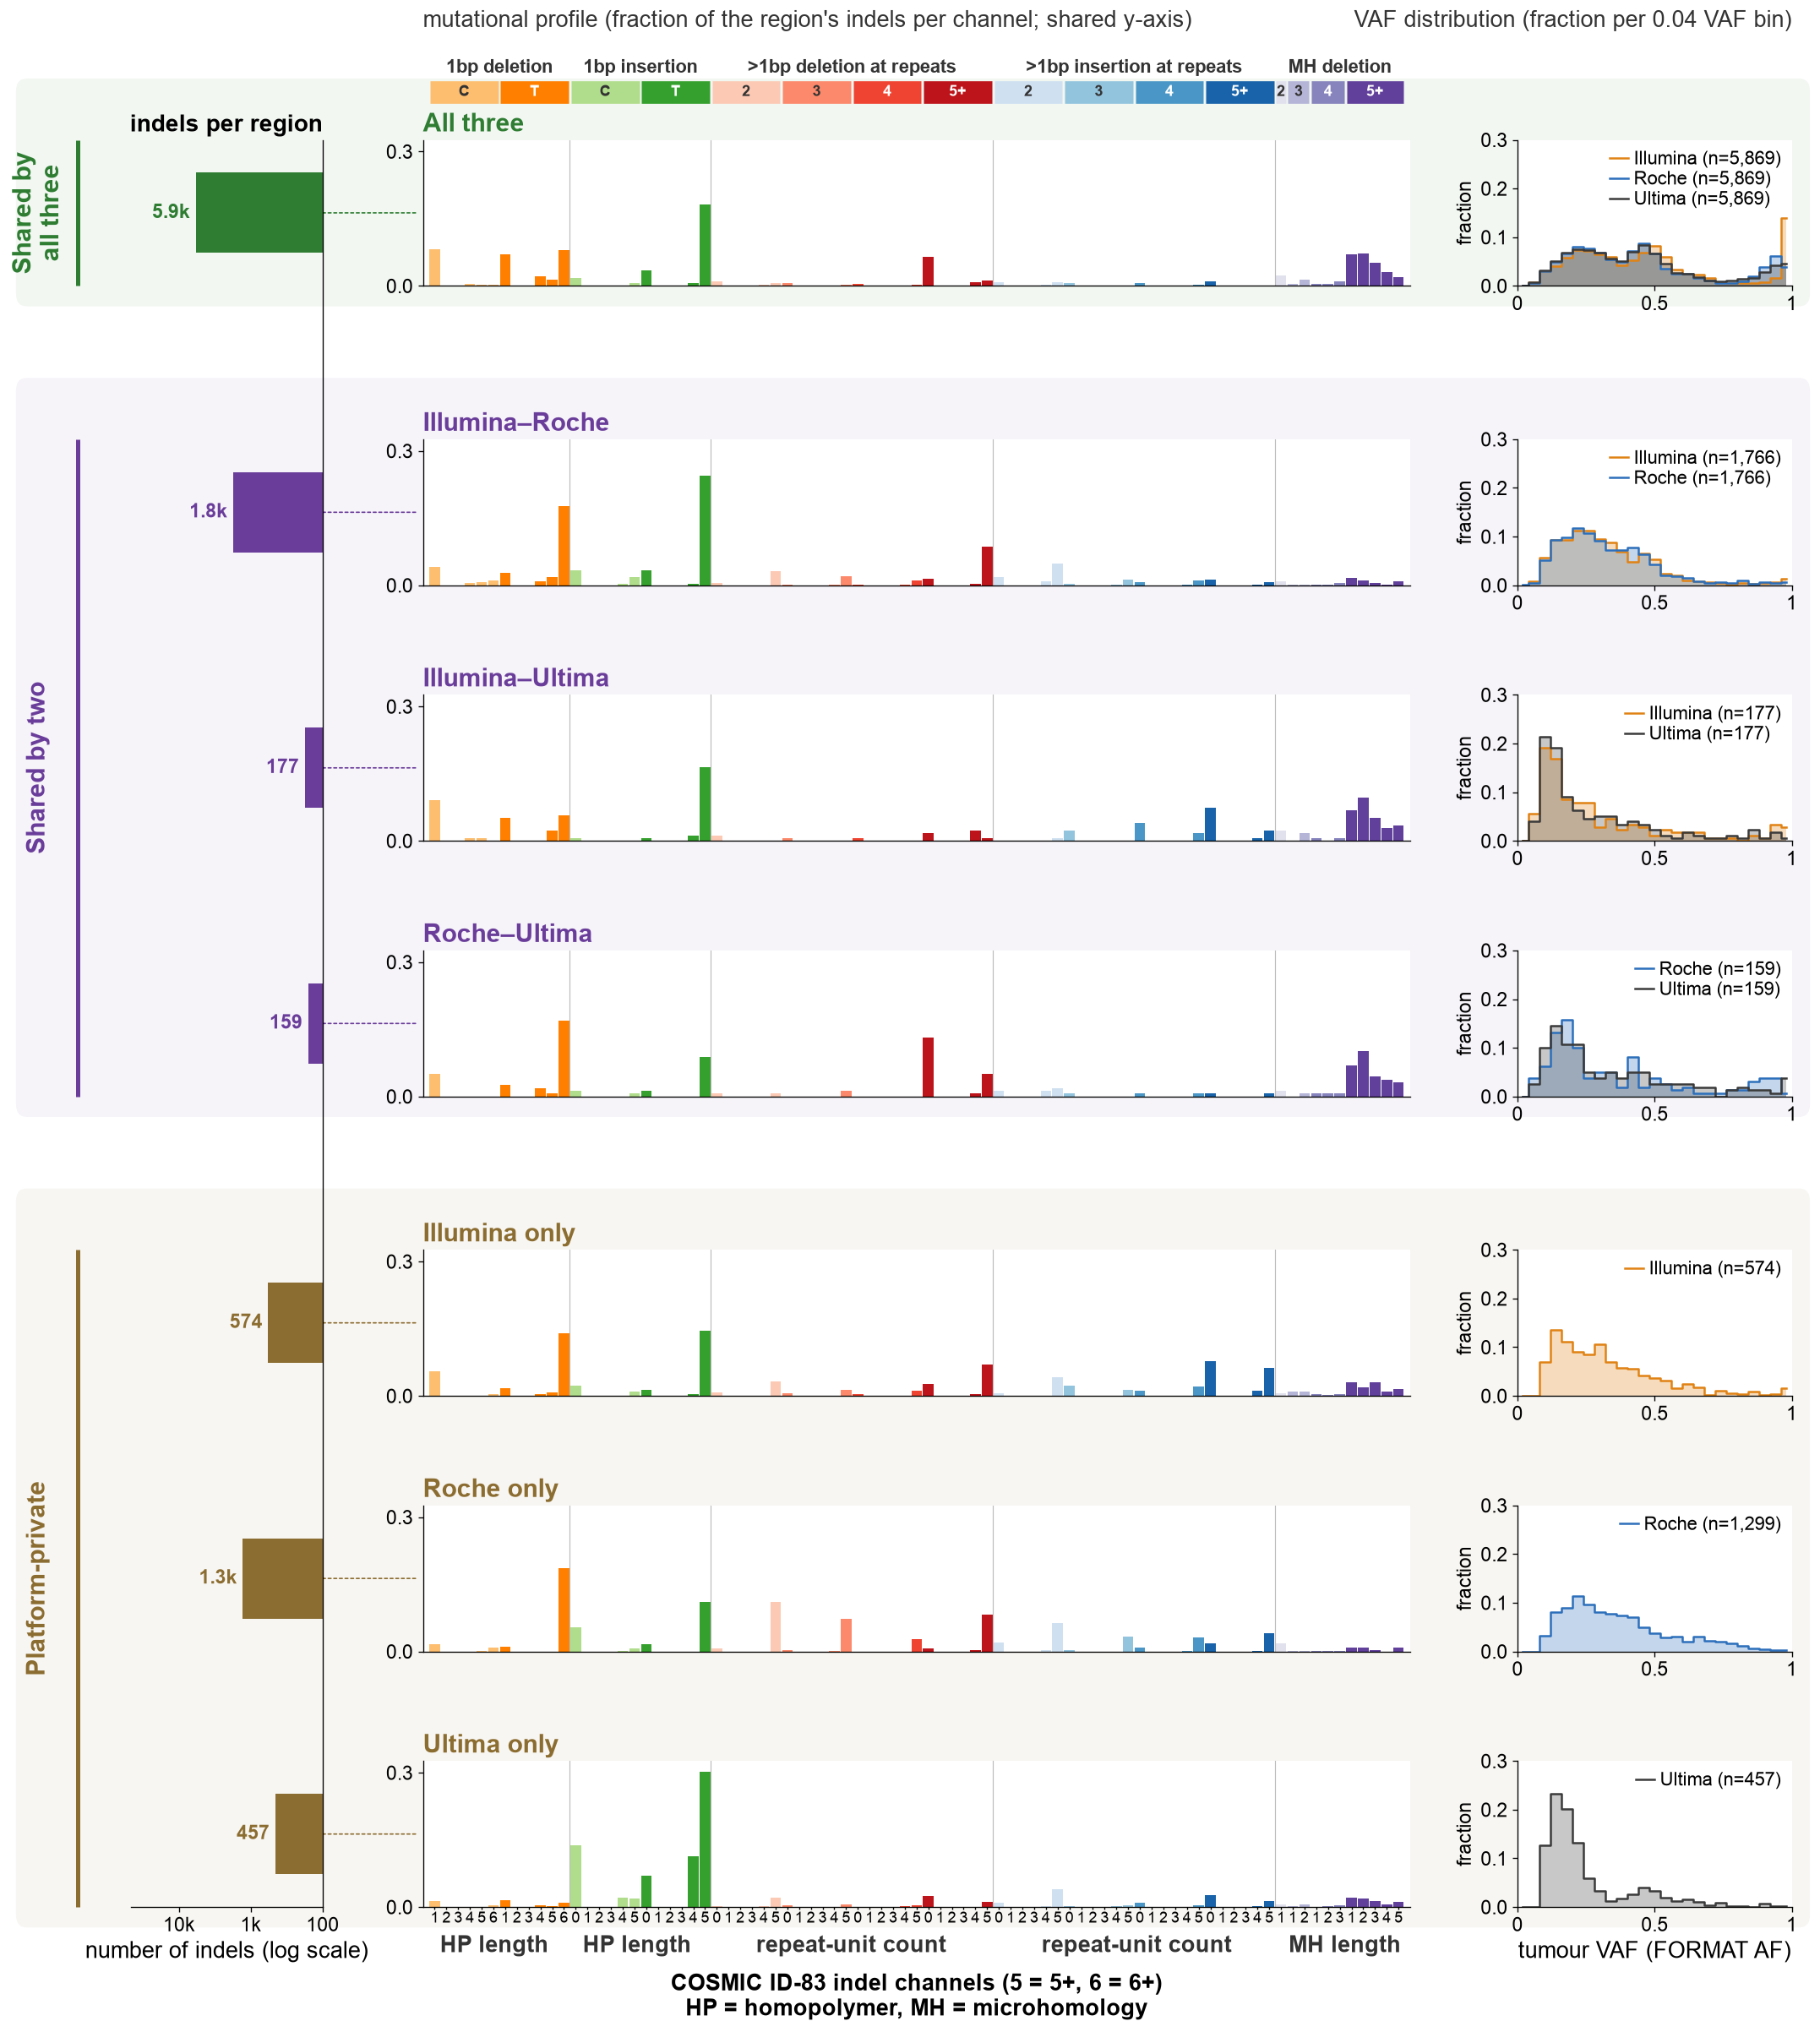

In [13]:
fig = draw_region_profiles("indel")
plt.show()